In [ ]:
import pandas as pd


In [ ]:
df = pd.read_csv("iris.data", header=None)

df.columns = [
    "sepal length",
    "sepal width",
    "petal length",
    "petal width",
    "class"
]

In [ ]:
df.head(10)

,sepal length,sepal width,petal length,petal width,class
0,5.1,3.5,1.4,0.2,Iris-setosa
1,4.9,3.0,1.4,0.2,Iris-setosa
2,4.7,3.2,1.3,0.2,Iris-setosa
3,4.6,3.1,1.5,0.2,Iris-setosa
4,5.0,3.6,1.4,0.2,Iris-setosa
5,5.4,3.9,1.7,0.4,Iris-setosa
6,4.6,3.4,1.4,0.3,Iris-setosa
7,5.0,3.4,1.5,0.2,Iris-setosa
8,4.4,2.9,1.4,0.2,Iris-setosa
9,4.9,3.1,1.5,0.1,Iris-setosa


In [ ]:
df.shape

(150, 5)

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   sepal length  150 non-null    float64
 1   sepal width   150 non-null    float64
 2   petal length  150 non-null    float64
 3   petal width   150 non-null    float64
 4   class         150 non-null    object 
dtypes: float64(4), object(1)
memory usage: 6.0+ KB


In [ ]:
df.describe

<bound method NDFrame.describe of      sepal length  sepal width  petal length  petal width           class
0             5.1          3.5           1.4          0.2     Iris-setosa
1             4.9          3.0           1.4          0.2     Iris-setosa
2             4.7          3.2           1.3          0.2     Iris-setosa
3             4.6          3.1           1.5          0.2     Iris-setosa
4             5.0          3.6           1.4          0.2     Iris-setosa
..            ...          ...           ...          ...             ...
145           6.7          3.0           5.2          2.3  Iris-virginica
146           6.3          2.5           5.0          1.9  Iris-virginica
147           6.5          3.0           5.2          2.0  Iris-virginica
148           6.2          3.4           5.4          2.3  Iris-virginica
149           5.9          3.0           5.1          1.8  Iris-virginica

[150 rows x 5 columns]>

In [ ]:
df.dtypes

,0
sepal length,float64
sepal width,float64
petal length,float64
petal width,float64
class,object


In [ ]:
df.isnull().sum()

,0
sepal length,0
sepal width,0
petal length,0
petal width,0
class,0


In [ ]:
print(df.duplicated().sum())

3


In [ ]:
df = df.drop_duplicates()

In [ ]:
df.shape

(147, 5)

In [ ]:
print(df.duplicated().sum())

0


In [ ]:
from sklearn.preprocessing import LabelEncoder, MinMaxScaler, StandardScaler

In [ ]:
le = LabelEncoder()

In [ ]:
df.columns

Index(['sepal length', 'sepal width', 'petal length', 'petal width', 'class'], dtype='object')

In [ ]:
df["class"] = le.fit_transform(df['class'])

/tmp/ipykernel_565/1849246385.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df["class"] = le.fit_transform(df['class'])


In [ ]:
df.dtypes

,0
sepal length,float64
sepal width,float64
petal length,float64
petal width,float64
class,int64


In [ ]:
df.head()

,sepal length,sepal width,petal length,petal width,class
0,5.1,3.5,1.4,0.2,0
1,4.9,3.0,1.4,0.2,0
2,4.7,3.2,1.3,0.2,0
3,4.6,3.1,1.5,0.2,0
4,5.0,3.6,1.4,0.2,0


In [ ]:
numerical_cols = [
    'sepal length',
    'sepal width',
    'petal length',
    'petal width'
]

In [ ]:
m_scaler = MinMaxScaler()

m_df = m_scaler.fit_transform(df[numerical_cols])

In [ ]:
z_scaler = StandardScaler()

z_df = z_scaler.fit_transform(df[numerical_cols])

convert to dataframe

In [ ]:
m_df = pd.DataFrame(m_df, columns=numerical_cols)
z_df = pd.DataFrame(z_df, columns=numerical_cols)

In [ ]:
m_df.head()

,sepal length,sepal width,petal length,petal width
0,0.222222,0.625000,0.067797,0.041667
1,0.166667,0.416667,0.067797,0.041667
2,0.111111,0.500000,0.050847,0.041667
3,0.083333,0.458333,0.084746,0.041667
4,0.194444,0.666667,0.067797,0.041667


In [ ]:
z_df.head()

,sepal length,sepal width,petal length,petal width
0,-0.915509,1.019971,-1.357737,-1.3357
1,-1.157560,-0.128082,-1.357737,-1.3357
2,-1.399610,0.331139,-1.414778,-1.3357
3,-1.520635,0.101529,-1.300696,-1.3357
4,-1.036535,1.249582,-1.357737,-1.3357


In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

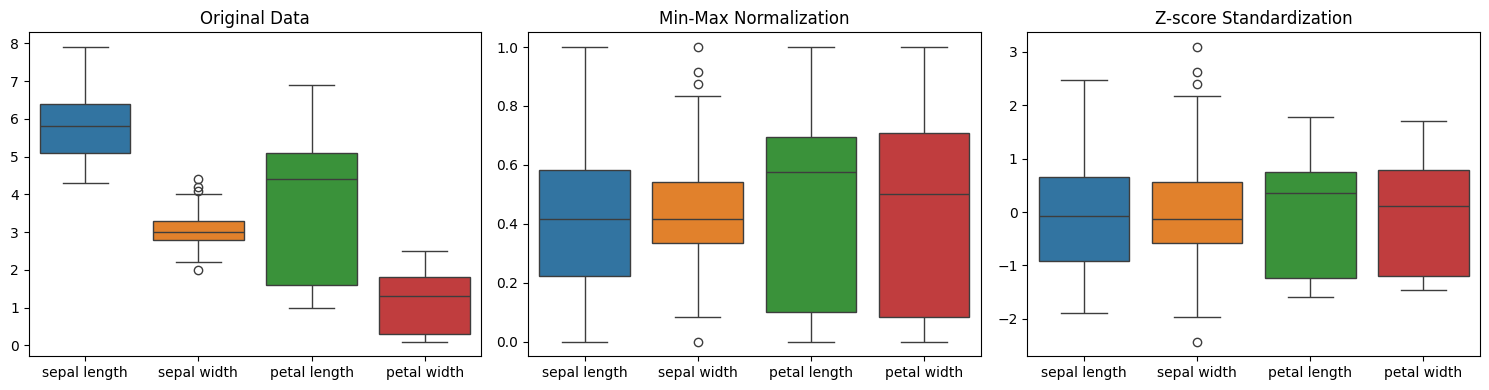

In [ ]:
fig, axes = plt.subplots(1,3, figsize=(15,4))

sns.boxplot(data=df[numerical_cols], ax=axes[0])
axes[0].set_title("Original Data")

sns.boxplot(data=m_df, ax=axes[1])
axes[1].set_title("Min-Max Normalization")

sns.boxplot(data=z_df, ax=axes[2])
axes[2].set_title("Z-score Standardization")

plt.tight_layout()
plt.show()